# Matplotlib and Seaborn for Data Analysis


**Simple idea:** Matplotlib is a plotting library that gives you detailed control over charts. Seaborn is built on top of Matplotlib and makes many statistical charts easier and more attractive.

If needed, install the libraries in a notebook cell:
```python
%pip install matplotlib seaborn pandas numpy
```

## 1. Import the libraries

- `pandas` helps us work with table-shaped data.
- `matplotlib.pyplot` helps us create and customize charts.
- `seaborn` makes statistical visualizations easier.
- `numpy` helps us create numeric data for examples.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts appear inside the notebook
%matplotlib inline

# Set a consistent default style for Seaborn charts
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Create a small sample dataset

We will use imaginary sales data for a small shop. You can reuse these examples to practice chart creation.

In [3]:
sales = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "Sales": [12000, 15000, 13500, 18000, 22000, 21000],
    "Profit": [2000, 2800, 2300, 3500, 4800, 4500],
    "Customers": [120, 145, 132, 170, 205, 198],
    "Category": ["Food", "Clothing", "Food", "Electronics", "Clothing", "Food"]
})

sales

,Month,Sales,Profit,Customers,Category
0,Jan,12000,2000,120,Food
1,Feb,15000,2800,145,Clothing
2,Mar,13500,2300,132,Food
3,Apr,18000,3500,170,Electronics
4,May,22000,4800,205,Clothing
5,Jun,21000,4500,198,Food


## 3. Matplotlib: Line chart

**Use it when:** you want to see how something changes over time.

**Example question:** How did sales change each month?

- `plt.plot()` draws the line.
- `marker="o"` adds a dot at each data point.
- `plt.xlabel()` and `plt.ylabel()` label the axes.
- `plt.title()` adds a chart title.

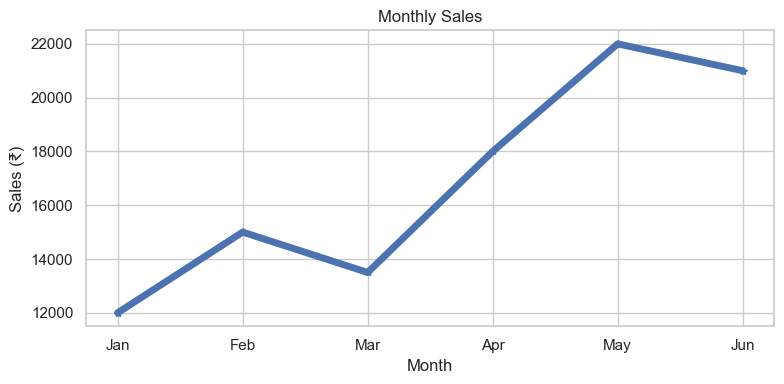

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(sales["Month"], sales["Sales"], marker="*", linewidth=5)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.grid(True, alpha=1)
plt.tight_layout()
plt.show()

## 4. Matplotlib: Bar chart

**Use it when:** you want to compare values between categories.

**Example question:** Which month had the highest sales?

`plt.bar()` creates vertical bars. The height of each bar represents the sales value.

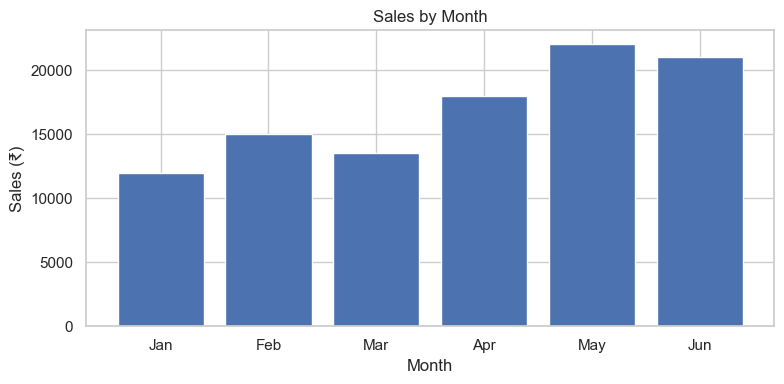

In [14]:
plt.figure(figsize=(8, 4))
plt.bar(sales["Month"], sales["Sales"])
plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.tight_layout()
plt.show()

## 5. Matplotlib: Scatter plot

**Use it when:** you want to check whether two numeric variables may be related.

**Example question:** Do months with more customers tend to have higher sales?

Each dot represents one month. A pattern may suggest a relationship, but it does not prove that one variable causes the other.

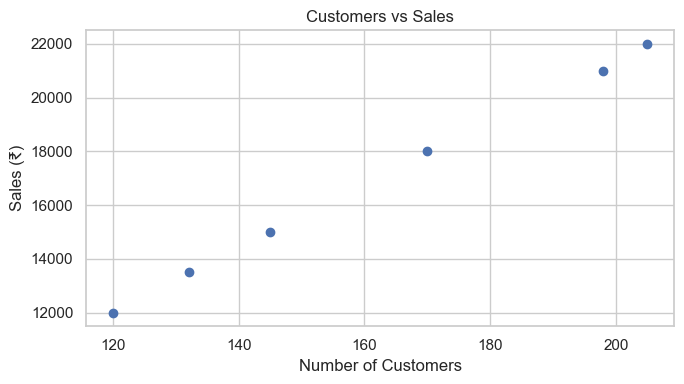

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(sales["Customers"], sales["Sales"])
plt.title("Customers vs Sales")
plt.xlabel("Number of Customers")
plt.ylabel("Sales (₹)")
plt.tight_layout()
plt.show()

## 6. Matplotlib: Histogram

A **histogram** shows how numeric values are distributed. It groups values into ranges called *bins*.

Here, we create example scores for students.

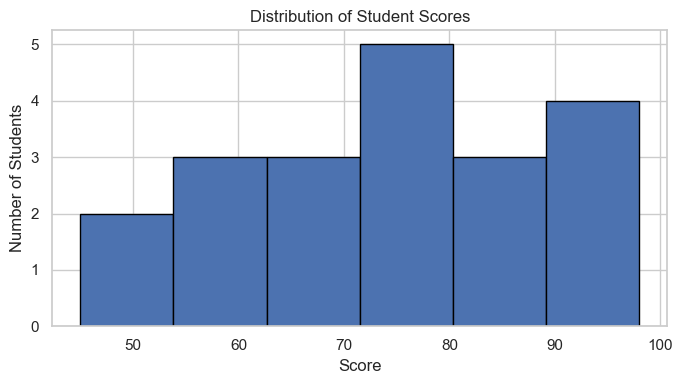

In [8]:
scores = [45, 52, 56, 60, 61, 65, 67, 70, 72, 74,
          75, 78, 80, 82, 85, 88, 90, 92, 95, 98]

plt.figure(figsize=(7, 4))
plt.hist(scores, bins=6, edgecolor="black")
plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

## 7. Matplotlib: Pie chart

**Use it when:** you want to show how a few categories make up a whole.

Pie charts become hard to read when there are too many categories. For many comparisons, a bar chart is often clearer.

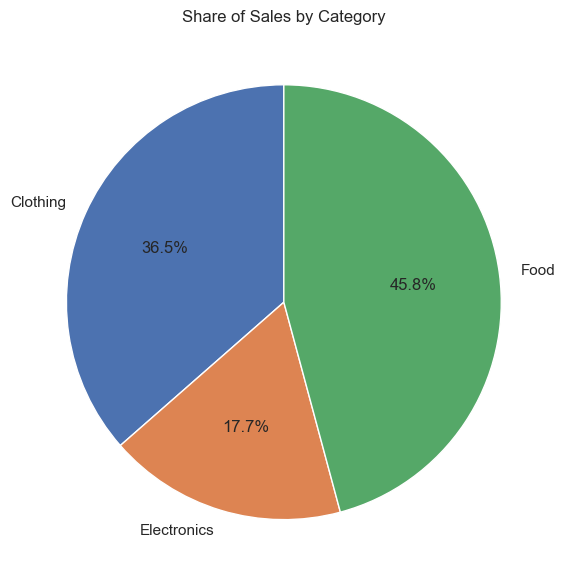

In [9]:
category_totals = sales.groupby("Category")["Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(
    category_totals,
    labels=category_totals.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of Sales by Category")
plt.tight_layout()
plt.show()

## 8. Seaborn: Why use it?

Seaborn works with Matplotlib but provides convenient functions for statistical charts and attractive defaults. It works especially well with Pandas DataFrames.

Let's use the same sales data.

## 9. Seaborn: Bar plot

A Seaborn `barplot` usually displays an estimated statistic (the mean by default) for each category. Since each month appears once in our data, each bar shows that month's sales.

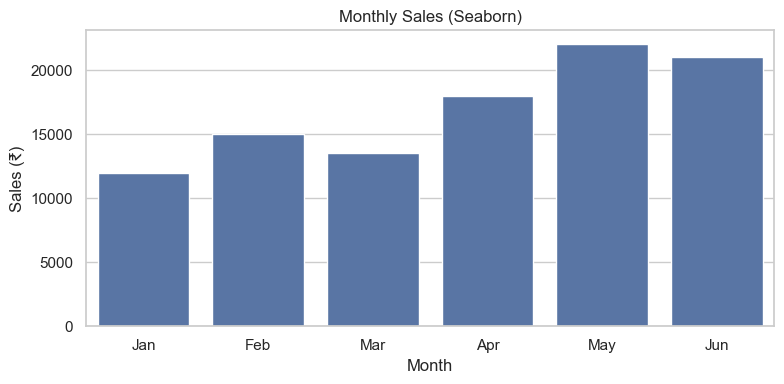

In [8]:
plt.figure(figsize=(8, 4))
sns.barplot(data=sales, x="Month", y="Sales")
plt.title("Monthly Sales (Seaborn)")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.tight_layout()
plt.show()

## 10. Seaborn: Count plot

A `countplot` counts how often each category appears.

**Example question:** Which product category occurs most often in our sample rows?

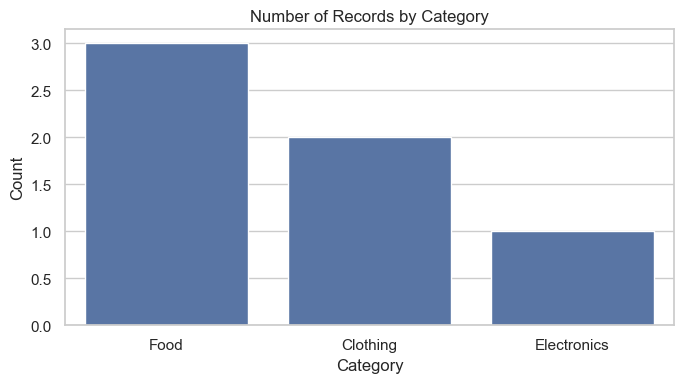

In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(data=sales, x="Category")
plt.title("Number of Records by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 11. Seaborn: Box plot

A box plot helps compare distributions and spot possible outliers.

- The line inside the box is the median.
- The box shows the middle 50% of values.
- Points beyond the whiskers may be possible outliers; investigate them rather than automatically deleting them.

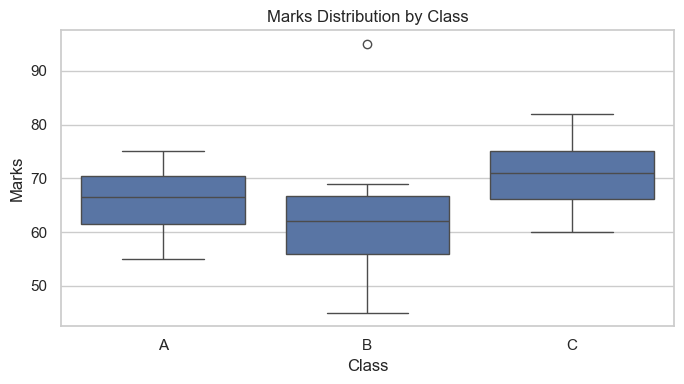

In [10]:
# Create example marks for three classes
marks = pd.DataFrame({
    "Class": ["A"] * 8 + ["B"] * 8 + ["C"] * 8,
    "Marks": [55, 60, 62, 65, 68, 70, 72, 75,
              45, 50, 58, 61, 63, 66, 69, 95,
              60, 64, 67, 70, 72, 74, 78, 82]
})

plt.figure(figsize=(7, 4))
sns.boxplot(data=marks, x="Class", y="Marks")
plt.title("Marks Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

## 12. Seaborn: Heatmap (correlation)

A **correlation** describes how two numeric variables move together:
- Near `+1`: strong positive linear relationship
- Near `-1`: strong negative linear relationship
- Near `0`: little or no linear relationship

Correlation does not prove cause and effect. A heatmap uses color to make the correlation table easier to scan.

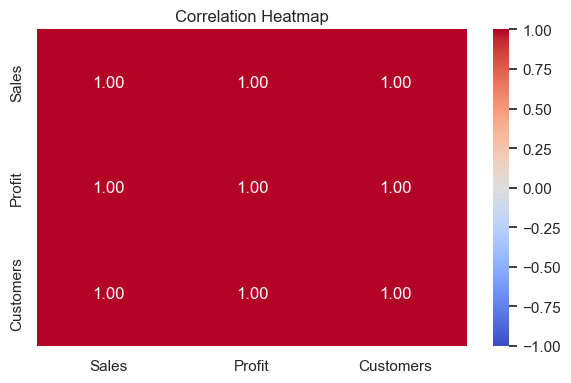

In [11]:
numeric_data = sales[["Sales", "Profit", "Customers"]]
correlation = numeric_data.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 13. Seaborn: Pair plot

A pair plot shows relationships between pairs of numeric columns. The diagonal shows the distribution of each variable.

It can be useful during Exploratory Data Analysis (EDA), but it may become crowded when you have many columns or many rows.

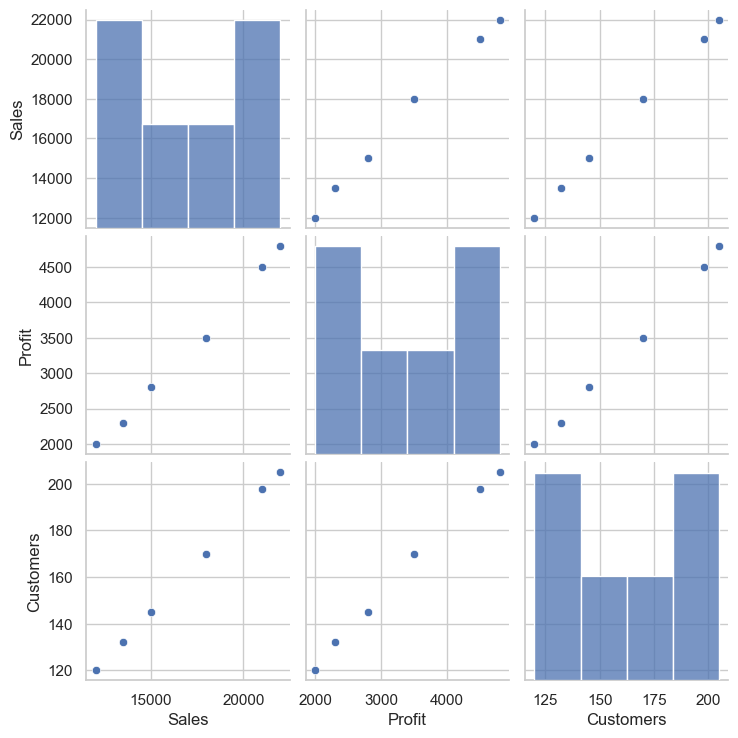

In [12]:
sns.pairplot(sales[["Sales", "Profit", "Customers"]])
plt.show()

## 14. Customize a chart

A good chart should have a clear title, readable labels, and units where needed. You can also add a legend when multiple lines are shown.

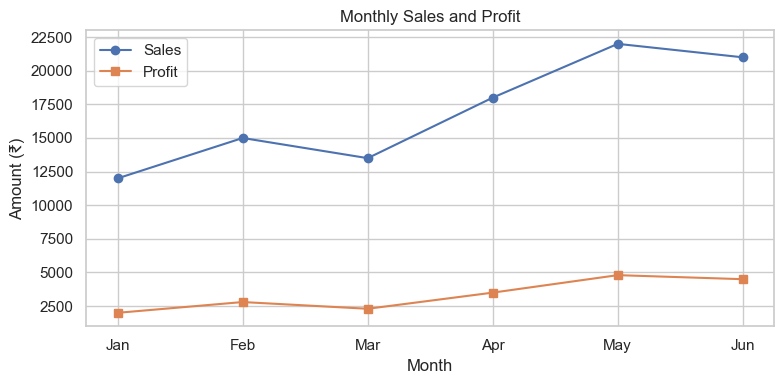

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(sales["Month"], sales["Sales"], marker="o", label="Sales")
plt.plot(sales["Month"], sales["Profit"], marker="s", label="Profit")
plt.title("Monthly Sales and Profit")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Matplotlib vs Seaborn

| Feature | Matplotlib | Seaborn |
|---|---|---|
| Main purpose | Flexible chart creation and customization | Convenient statistical visualizations |
| Best for | Detailed control and custom plots | Quick analysis of patterns and distributions |
| Data input | Lists, arrays, or DataFrames | Often works directly with DataFrames |
| Relationship | Base plotting library | Built on top of Matplotlib |

**Remember:** You can use both in the same project. Seaborn charts can be customized with Matplotlib functions such as `plt.title()`, `plt.xlabel()`, and `plt.tight_layout()`.

Use Seaborn to create the plot quickly and beautifully, but use Matplotlib to customize the details (like changing titles, labels, or figure sizes)

## 16. Which chart should I choose?

| Question | Good starting chart |
|---|---|
| How does a value change over time? | Line chart |
| Which category is bigger? | Bar chart |
| How are values distributed? | Histogram |
| Are two numeric variables related? | Scatter plot |
| Are there unusual values? | Box plot |
| How are numeric variables correlated? | Correlation heatmap |
| How often does each category appear? | Count plot |
| How is a whole divided among a few categories? | Pie chart (or bar chart) |



In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "day":  ["Mon","Mon","Tue","Tue","Wed","Wed","Thu","Thu"],
    "tip":  [3, 4, 5, 6, 2, 3, 7, 8],
    "sex":  ["M","F","M","F","M","F","M","F"],
})

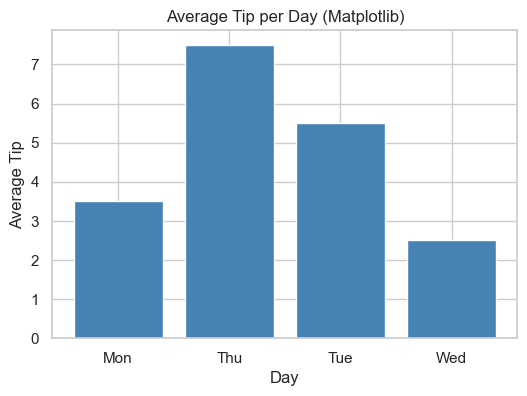

In [18]:
avg = df.groupby("day")["tip"].mean()      # calculate averages yourself

plt.figure(figsize=(6, 4))
plt.bar(avg.index, avg.values, color="steelblue")
plt.title("Average Tip per Day (Matplotlib)")
plt.xlabel("Day")
plt.ylabel("Average Tip")
plt.show()

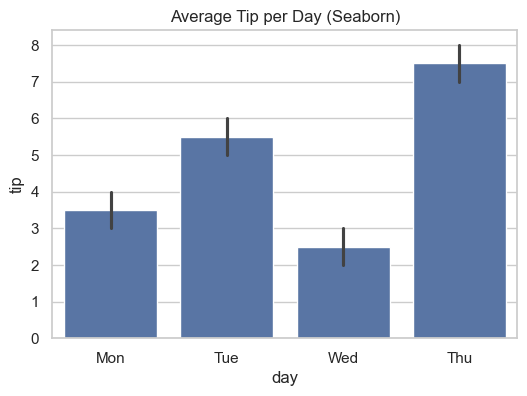

In [19]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="day", y="tip")     # averages + error bars automatically
plt.title("Average Tip per Day (Seaborn)")
plt.show()